# 00 — Connection Check

> **What it does:** verifies in a single run that this machine can reach every data source used across the 61 projects of `risk-quant-ml-lab`.
> **Data:** FRED, U.S. Treasury, Treasury Fiscal Data, Yahoo Finance, iShares holdings, SEC EDGAR, World Bank, FDIC, OFR, Ken French, DTCC swap reports and Kaggle.
> **Methods:** small live API calls with timeouts, credential checks from `.env`, package and Apple-GPU (MPS) checks, and a DuckDB summary.
> **Key output:** a ✅ / ❌ status table with the exact fix for anything that fails, plus a SOFR vs 10-year Treasury chart as proof of life.

## Why this notebook exists

Every project in this repo pulls its data live from the original source. That keeps the work reproducible, because anyone can clone the repo and rebuild every number. The cost is that a missing key or a moved URL only shows up halfway through a long notebook.

This notebook flushes those problems out first. Each check is tiny: one request, one small download, a timeout of a few seconds. Nothing is saved to disk. Run it whenever you set up a new machine, or whenever a project complains about data.

**How to read the results**

| Status | Meaning |
|---|---|
| ✅ OK | Source reachable and returning data. |
| ⚠️ FALLBACK | Primary source failed, but the backup the projects use instead works. Nothing to do. |
| ℹ️ MANUAL | Source needs a manual step (explained in the row). Not an error. |
| ❌ FAILED | Something to fix. The *How to fix* column says what. |

## 1. Setup

A small helper, `run_check`, runs each test, times it and records the outcome. A check *never* stops the notebook: if a source fails we write down why and move on to the next one.

In [1]:
import datetime as dt
import importlib
import importlib.metadata as md
import io
import os
import platform
import sys
import time
import warnings
import zipfile

import pandas as pd
import requests
from dotenv import find_dotenv, load_dotenv

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 140)

TIMEOUT = 25            # seconds per request — generous, but never hangs forever
TODAY = dt.date.today()

# Some public sites (iShares, Treasury) reject requests that don't look like a browser.
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "
        "AppleWebKit/537.36 (KHTML, like Gecko) Chrome/130.0 Safari/537.36"
    )
}

RESULTS = []   # one dict per check
CACHE = {}     # small pieces of data reused by the final chart


class Fallback(Exception):
    """Raised by a check when the primary source failed but a backup worked."""


class Manual(Exception):
    """Raised by a check that needs a manual step rather than a live call."""


def run_check(name, used_by, check_fn, how_to_fix):
    """Run one check, print a one-line verdict and store the result."""
    start = time.perf_counter()
    try:
        detail = check_fn()
        status = "✅ OK"
    except Fallback as note:
        status, detail = "⚠️ FALLBACK", str(note)
    except Manual as note:
        status, detail = "ℹ️ MANUAL", str(note)
    except Exception as err:  # any failure is recorded, never raised
        status, detail = "❌ FAILED", f"{type(err).__name__}: {err}"[:300]
    elapsed = time.perf_counter() - start

    RESULTS.append({
        "source": name,
        "status": status,
        "detail": detail,
        "used_by": used_by,
        "how_to_fix": "" if status.startswith(("✅", "⚠️")) else how_to_fix,
        "seconds": round(elapsed, 1),
    })
    print(f"{status:<12} {name}  ({elapsed:.1f}s)\n             {detail}")
    if status.startswith("❌"):
        print(f"             How to fix: {how_to_fix}")


def get(url, **kwargs):
    """requests.get with a timeout and an exception on HTTP errors."""
    kwargs.setdefault("timeout", TIMEOUT)
    response = requests.get(url, **kwargs)
    response.raise_for_status()
    return response


print(f"Run date: {TODAY:%Y-%m-%d} · Python {platform.python_version()} · {platform.platform()}")

Run date: 2026-10-18 · Python 3.12.15 · macOS-27.0-arm64-arm-64bit


## 2. Local environment

Before touching the network, make sure the machine itself is ready:

- **Python version.** The repo targets 3.12.
- **Packages.** Every library in `requirements.txt` must import.
- **Apple GPU.** PyTorch should see the M1 chip through *MPS* (Metal Performance Shaders). The deep-learning projects use it to train several times faster than on the CPU.

In [2]:
def check_python():
    version = sys.version_info
    if (version.major, version.minor) != (3, 12):
        raise RuntimeError(f"running Python {platform.python_version()}, expected 3.12")
    return f"Python {platform.python_version()} on {platform.machine()}"

run_check("Python version", "all projects", check_python,
          "Select the kernel 'Python (quant-risk)' (top right in VS Code).")


# Distribution name on PyPI -> module name used in `import`
PACKAGES = {
    "numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "pyarrow": "pyarrow",
    "duckdb": "duckdb", "matplotlib": "matplotlib", "seaborn": "seaborn",
    "plotly": "plotly", "kaleido": "kaleido", "statsmodels": "statsmodels",
    "arch": "arch", "hmmlearn": "hmmlearn", "ruptures": "ruptures",
    "statsforecast": "statsforecast", "scikit-learn": "sklearn", "xgboost": "xgboost",
    "lightgbm": "lightgbm", "catboost": "catboost", "imbalanced-learn": "imblearn",
    "optuna": "optuna", "shap": "shap", "lifelines": "lifelines",
    "scikit-survival": "sksurv", "pymc": "pymc", "arviz": "arviz", "cvxpy": "cvxpy",
    "pyportfolioopt": "pypfopt", "QuantLib": "QuantLib", "torch": "torch",
    "torch-geometric": "torch_geometric", "neuralforecast": "neuralforecast",
    "gymnasium": "gymnasium", "stable-baselines3": "stable_baselines3",
    "transformers": "transformers", "sentence-transformers": "sentence_transformers",
    "spacy": "spacy", "mlflow": "mlflow", "beautifulsoup4": "bs4", "lxml": "lxml",
    "yfinance": "yfinance", "fredapi": "fredapi", "kaggle": "kaggle",
    "ucimlrepo": "ucimlrepo", "python-dotenv": "dotenv", "tqdm": "tqdm",
}


def check_packages():
    # We only read installed versions here (fast). Importing everything would
    # take a minute because of torch/transformers, and versions are what matter.
    missing, versions = [], {}
    for dist in PACKAGES:
        try:
            versions[dist] = md.version(dist)
        except md.PackageNotFoundError:
            missing.append(dist)
    if missing:
        raise RuntimeError(f"{len(missing)} missing: {', '.join(missing)}")
    CACHE["package_versions"] = versions
    return f"all {len(PACKAGES)} key packages installed"

run_check("Python packages", "all projects", check_packages,
          "conda activate quant-risk && conda install -c conda-forge ecos -y && "
          "pip install -r requirements.txt")


def check_mps():
    import torch
    if not torch.backends.mps.is_available():
        raise RuntimeError(f"torch {torch.__version__} installed but MPS not available")
    x = torch.ones(3, device="mps") * 2          # tiny computation on the GPU
    return f"torch {torch.__version__} · MPS available · test tensor sum = {x.sum().item():.0f}"

run_check("PyTorch on Apple GPU (MPS)", "deep-learning projects", check_mps,
          "Needs macOS 14+ on Apple Silicon and torch from requirements.txt. "
          "Projects still run on CPU if this fails, only slower.")

✅ OK         Python version  (0.0s)
             Python 3.12.15 on arm64
✅ OK         Python packages  (0.0s)
             all 45 key packages installed
✅ OK         PyTorch on Apple GPU (MPS)  (7.1s)
             torch 2.14.1 · MPS available · test tensor sum = 6


## 3. Credentials

Keys live in a `.env` file at the repo root and are loaded into environment variables. They never appear in the code and never reach GitHub, because `.gitignore` excludes them. Below we only check that they exist and *look* right; the values are never printed.

In [3]:
ENV_PATH = find_dotenv(usecwd=True)
load_dotenv(ENV_PATH, override=True)

FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
SEC_USER_AGENT = os.getenv("SEC_USER_AGENT", "").strip()


def check_env_file():
    if not ENV_PATH:
        raise FileNotFoundError("no .env file found in this folder or its parents")
    problems = []
    if not (len(FRED_API_KEY) == 32 and FRED_API_KEY.isalnum()):
        problems.append("FRED_API_KEY should be 32 letters/digits")
    if "@" not in SEC_USER_AGENT or " " not in SEC_USER_AGENT:
        problems.append("SEC_USER_AGENT should look like 'Your Name your@email.com'")
    if problems:
        raise ValueError("; ".join(problems))
    masked = FRED_API_KEY[:3] + "…" + FRED_API_KEY[-2:]
    return f".env found · FRED key {masked} · SEC user agent set"

run_check(".env credentials", "FRED and SEC projects", check_env_file,
          "Copy .env.example to .env and fill in both values (KEY=value, no spaces or quotes).")

✅ OK         .env credentials  (0.0s)
             .env found · FRED key 7a7…75 · SEC user agent set


## 4. Rates & macro sources

These feed almost every fixed-income, counterparty and liquidity project:

- **FRED** (St. Louis Fed) for SOFR, Treasury constant-maturity yields, credit spreads and macro series.
- **U.S. Treasury** for the official daily par yield curve, the input for curve building.
- **Treasury Fiscal Data** for the Daily Treasury Statement, used in the cash-forecasting project.

In [4]:
def check_fred():
    from fredapi import Fred
    fred = Fred(api_key=FRED_API_KEY)
    start = TODAY - dt.timedelta(days=730)
    sofr = fred.get_series("SOFR", observation_start=start).dropna()
    ust10 = fred.get_series("DGS10", observation_start=start).dropna()
    CACHE["sofr"], CACHE["ust10"] = sofr, ust10
    return (f"SOFR {sofr.iloc[-1]:.2f}% on {sofr.index[-1]:%Y-%m-%d} · "
            f"10Y UST {ust10.iloc[-1]:.2f}% · {len(sofr)} daily obs. downloaded")

run_check("FRED API", "A, D, F, G, H blocks", check_fred,
          "Check FRED_API_KEY in .env (https://fredaccount.stlouisfed.org/apikeys).")


def treasury_curve_url(year):
    return ("https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
            f"daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
            f"&field_tdr_date_value={year}&page&_format=csv")


def check_treasury_curve():
    # Early January the current-year file can be empty, so fall back one year.
    for year in (TODAY.year, TODAY.year - 1):
        text = get(treasury_curve_url(year), headers=BROWSER_HEADERS).text
        curve = pd.read_csv(io.StringIO(text))
        if len(curve):
            latest = curve.iloc[0]   # the file is sorted newest first
            return (f"{len(curve)} curves in {year} · latest {latest['Date']} · "
                    f"10Y = {latest['10 Yr']}%")
    raise RuntimeError("Treasury returned an empty file")

run_check("U.S. Treasury par yield curve", "yield curves, fixed income, IRRBB",
          check_treasury_curve,
          "Open https://home.treasury.gov/resource-center/data-chart-center/interest-rates "
          "in a browser; if it loads, retry in a minute.")


def check_fiscal_data():
    url = ("https://api.fiscaldata.treasury.gov/services/api/fiscal_service/"
           "v1/accounting/dts/operating_cash_balance")
    params = {"sort": "-record_date", "page[size]": 1}
    record = get(url, params=params).json()["data"][0]
    return f"Daily Treasury Statement available up to {record['record_date']}"

run_check("Treasury Fiscal Data API", "treasury cash forecasting", check_fiscal_data,
          "Public API, no key. Retry later; check https://fiscaldata.treasury.gov/.")

✅ OK         FRED API  (2.1s)
             SOFR 3.89% on 2026-10-15 · 10Y UST 5.10% · 496 daily obs. downloaded
✅ OK         U.S. Treasury par yield curve  (1.0s)
             199 curves in 2026 · latest 10/16/2026 · 10Y = 5.09%
✅ OK         Treasury Fiscal Data API  (1.0s)
             Daily Treasury Statement available up to 2026-10-15


## 5. Market data

- **Yahoo Finance** through `yfinance` supplies prices for US ETFs, indices, FX (including COP, MXN, BRL and CLP for the local-currency project) and SOFR futures. The API is unofficial, so the projects cache whatever they download.
- **iShares holdings files** contain the real bond-by-bond portfolios (coupon, maturity, price, yield) behind the MDB-style treasury portfolio of block H.

In [5]:
def check_yahoo():
    import logging
    import yfinance as yf
    logging.getLogger("yfinance").setLevel(logging.CRITICAL)   # keep the output readable
    tickers = ["SPY", "^TNX", "COP=X", "MXN=X", "BRL=X", "CLP=X", "SR3=F"]
    prices = yf.download(tickers, period="1mo", progress=False, auto_adjust=True)["Close"]
    got = [t for t in tickers if t in prices and prices[t].notna().any()]
    missing = sorted(set(tickers) - set(got))
    if not got:
        raise RuntimeError("Yahoo returned no data for any ticker")
    detail = f"{len(got)}/{len(tickers)} tickers returned prices"
    if missing:
        detail += f" (no data for: {', '.join(missing)})"
        raise Fallback(detail + " — partial data is normal if Yahoo throttles; rerun later")
    return detail

run_check("Yahoo Finance", "market risk, valuation, portfolios", check_yahoo,
          "Wait a minute and rerun (Yahoo throttles bursts). Check https://finance.yahoo.com loads.")


ISHARES_FUNDS = {
    # ticker: (product id, URL slug) — from each fund's page on ishares.com
    "GOVT": ("239468", "ishares-u-s-treasury-bond-etf"),
}


def check_ishares():
    ticker, (pid, slug) = next(iter(ISHARES_FUNDS.items()))
    url = f"https://www.ishares.com/us/products/{pid}/{slug}/latest-holdings.csv"
    lines = get(url, headers=BROWSER_HEADERS).text.splitlines()
    # The file starts with a few lines of fund metadata, then the holdings table.
    as_of = next((l.split(",", 1)[1].strip('" ') for l in lines if "as of" in l.lower()), "?")
    header_row = next(i for i, l in enumerate(lines) if l.startswith(("Ticker", "Name")))
    holdings = pd.read_csv(io.StringIO("\n".join(lines[header_row:])), on_bad_lines="skip")
    holdings = holdings.dropna(subset=[holdings.columns[1]])
    return f"{ticker}: {len(holdings)} holdings as of {as_of} · columns: {', '.join(holdings.columns[:6])}…"

run_check("iShares fund holdings", "bond portfolios and hedging", check_ishares,
          "Open https://www.ishares.com/us/products/239468/ in a browser; if the site works, "
          "iShares may have changed the file format — tell Claude.")

✅ OK         Yahoo Finance  (2.9s)
             7/7 tickers returned prices
✅ OK         iShares fund holdings  (0.5s)
             GOVT: 231 holdings as of Oct 15, 2026 · columns: Name, Sector, Asset Class, Market Value, Weight (%), Notional Value…


## 6. Swap trade data (DTCC)

Under the CFTC rules, every US-reportable swap is published anonymously by the swap data repositories. DTCC posts a **cumulative daily file** per asset class, and one project builds a SOFR swap curve directly from those reported trades. Files are kept for roughly one year, so we only check that a recent one exists, using a `HEAD` request that reads the file size without downloading it.

In [6]:
def dtcc_url(day):
    return ("https://kgc0418-tdw-data-0.s3.amazonaws.com/cftc/eod/"
            f"CFTC_CUMULATIVE_RATES_{day:%Y_%m_%d}.zip")


def check_dtcc():
    day = TODAY
    for _ in range(10):                      # walk back over weekends / holidays
        day -= dt.timedelta(days=1)
        if day.weekday() >= 5:
            continue
        head = requests.head(dtcc_url(day), timeout=TIMEOUT)
        if head.status_code == 200:
            size_mb = int(head.headers.get("Content-Length", 0)) / 1e6
            return f"latest rates file: {day:%Y-%m-%d} ({size_mb:.1f} MB zipped)"
    raise RuntimeError(f"no rates file found in the last 10 days (last status {head.status_code})")

run_check("DTCC public swap reports", "trade-based SOFR curve", check_dtcc,
          "Check https://pddata.dtcc.com/ppd/cftcdashboard loads; DTCC may have changed the "
          "file location — tell Claude.")

✅ OK         DTCC public swap reports  (1.7s)
             latest rates file: 2026-10-16 (1.3 MB zipped)


## 7. Credit, bank & macro sources

- **SEC EDGAR** supplies XBRL financial statements, ISDA/CSA exhibits, ABS-EE loan tapes and 10-K text. It requires a `User-Agent` with a name and email on every request.
- **World Bank** provides country macro panels for the sovereign PD project.
- **FDIC BankFind** provides balance sheets and failure history of every US bank.
- **OFR Financial Stress Index** feeds the funding-stress early-warning system. If the OFR file is unavailable, the projects switch to the St. Louis Fed index on FRED.
- **Ken French Data Library** provides the classic equity factors.

In [7]:
def check_sec():
    headers = {"User-Agent": SEC_USER_AGENT, "Accept-Encoding": "gzip, deflate"}
    data = get("https://data.sec.gov/submissions/CIK0000320193.json", headers=headers).json()
    n_filings = len(data["filings"]["recent"]["accessionNumber"])
    return f"EDGAR answered: {data['name']} · {n_filings} recent filings listed"

run_check("SEC EDGAR", "ISDA NLP, ABS pools, XBRL valuation, AI reporting", check_sec,
          "Set SEC_USER_AGENT in .env as 'Your Name your@email.com'. The SEC blocks requests without it.")


def check_world_bank():
    url = "https://api.worldbank.org/v2/country/USA/indicator/NY.GDP.MKTP.CD"
    meta, rows = get(url, params={"format": "json", "per_page": 5, "mrv": 1}).json()
    row = rows[0]
    return f"US GDP {row['date']}: ${float(row['value']) / 1e12:.1f} trn ({meta['total']} obs. available)"

run_check("World Bank API", "sovereign PD", check_world_bank,
          "Public API, no key. Retry later; check https://data.worldbank.org/.")


def check_fdic():
    params = {"filters": "ACTIVE:1", "fields": "NAME,CERT", "limit": 1}
    for base in ("https://api.fdic.gov/banks/institutions",
                 "https://banks.data.fdic.gov/api/institutions"):
        try:
            data = get(base, params=params).json()
            return f"{data['meta']['total']:,} active US institutions listed ({base.split('/')[2]})"
        except Exception as err:
            last_error = err
    raise last_error

run_check("FDIC BankFind API", "bank failure, contagion network", check_fdic,
          "Public API, no key. Check https://api.fdic.gov/banks/docs/ loads.")


def check_ofr_fsi():
    url = "https://www.financialresearch.gov/financial-stress-index/data/fsi.csv"
    try:
        fsi = pd.read_csv(io.StringIO(get(url, headers=BROWSER_HEADERS).text))
        return f"OFR FSI: {len(fsi)} daily obs., latest {fsi.iloc[-1, 0]}"
    except Exception as err:
        from fredapi import Fred
        stl = Fred(api_key=FRED_API_KEY).get_series("STLFSI4").dropna()
        raise Fallback(f"OFR file unavailable ({type(err).__name__}); FRED STLFSI4 works "
                       f"(latest {stl.index[-1]:%Y-%m-%d})")

run_check("OFR Financial Stress Index", "funding stress early warning", check_ofr_fsi,
          "No action needed if FRED works: the funding-stress project uses the St. Louis Fed stress index as backup.")


def check_ken_french():
    url = ("https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
           "F-F_Research_Data_Factors_CSV.zip")
    archive = zipfile.ZipFile(io.BytesIO(get(url).content))
    return f"factor file downloaded: {', '.join(archive.namelist())}"

run_check("Ken French Data Library", "ML factor models", check_ken_french,
          "Check https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html loads.")

✅ OK         SEC EDGAR  (1.1s)
             EDGAR answered: Apple Inc. · 1000 recent filings listed
✅ OK         World Bank API  (15.9s)
             US GDP 2025: $30.8 trn (1 obs. available)
✅ OK         FDIC BankFind API  (1.3s)
             4,219 active US institutions listed (api.fdic.gov)
✅ OK         OFR Financial Stress Index  (0.6s)
             OFR FSI: 6780 daily obs., latest 2026-10-14
✅ OK         Ken French Data Library  (0.7s)
             factor file downloaded: F-F_Research_Data_Factors.csv


## 8. Kaggle & Freddie Mac

- **Kaggle** hosts the credit-default, LGD, rating and churn datasets of block B. The token lives in `~/.kaggle/access_token`. Competition data (Home Credit) also requires accepting the rules on the website once.
- **Freddie Mac** loan-level mortgage data needs a manual download after logging in, and its licence forbids redistribution. We only check whether the files are already in place. They are needed from Paquete 12 onwards.

In [8]:
def _names(listing):
    files = getattr(listing, "files", listing) or []
    return [getattr(f, "name", str(f)) for f in files]


def check_kaggle_competition():
    import kaggle                            # authenticates on import
    files = _names(kaggle.api.competition_list_files("home-credit-default-risk"))
    if not files:
        raise RuntimeError("authenticated, but the competition returned no files")
    return f"authenticated · Home Credit competition: {len(files)} files visible (e.g. {files[0]})"

run_check("Kaggle — Home Credit competition", "ML PD model, model validation", check_kaggle_competition,
          "If 401: recreate ~/.kaggle/access_token with a new token. If 403: open "
          "https://www.kaggle.com/competitions/home-credit-default-risk/rules and accept.")


KAGGLE_DATASETS = {
    "BankChurners": "sakshigoyal7/credit-card-customers",
    "Bank Customer Churn": "radheshyamkollipara/bank-customer-churn",
    "Corporate Credit Rating": "agewerc/corporate-credit-rating",
    "Lending Club": "wordsforthewise/lending-club",
}


def check_kaggle_datasets():
    import kaggle
    ok, failed = [], []
    for label, ref in KAGGLE_DATASETS.items():
        try:
            _names(kaggle.api.dataset_list_files(ref))
            ok.append(label)
        except Exception:
            failed.append(label)
    if not ok:
        raise RuntimeError(f"no dataset reachable: {', '.join(failed)}")
    if failed:
        raise Fallback(f"{len(ok)}/{len(KAGGLE_DATASETS)} datasets reachable; "
                       f"not reachable: {', '.join(failed)} — Claude will pick an alternative")
    return f"all {len(ok)} datasets reachable"

run_check("Kaggle — public datasets", "LGD, ratings, churn", check_kaggle_datasets,
          "Same token as above. If only some fail, the dataset may have been renamed — tell Claude.")


def check_freddie_mac():
    folder = os.path.join(os.getcwd(), "data", "freddie_mac")
    if os.path.isdir(folder) and os.listdir(folder):
        return f"{len(os.listdir(folder))} file(s) found in {folder}"
    raise Manual("not downloaded yet — only needed for the mortgage projects; "
                 "each notebook gives the exact link and file name")

run_check("Freddie Mac loan-level data", "mortgage and securitization projects", check_freddie_mac,
          "Download from https://claritydownload.fmapps.freddiemac.com/CRT/#/sflld when we reach Paquete 12.")

Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token
❌ FAILED     Kaggle — Home Credit competition  (0.9s)
             HTTPError: 401 Client Error: Unauthorized for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/ListDataFiles
             How to fix: If 401: recreate ~/.kaggle/access_token with a new token. If 403: open https://www.kaggle.com/competitions/home-cre

## 9. Summary

The table collects every check. DuckDB, the in-process SQL engine used across the repo for ETL and exposure reporting, produces the scorecard below directly from the pandas DataFrame, so its check is built in.

In [9]:
import duckdb

results = pd.DataFrame(RESULTS)

scorecard = duckdb.sql("""
    SELECT split_part(status, ' ', 2)  AS outcome,
           COUNT(*)                    AS checks,
           ROUND(SUM(seconds), 1)      AS total_seconds
    FROM results
    GROUP BY outcome
    ORDER BY checks DESC
""").df()

print(f"DuckDB {duckdb.__version__} · {len(results)} checks run\n")
print(scorecard.to_string(index=False))

failed = results[results["status"].str.startswith("❌")]
print("\n" + ("Everything needed right now is reachable. 🎉" if failed.empty
              else f"{len(failed)} check(s) need attention — see 'how_to_fix' below."))

results[["source", "status", "detail", "used_by", "how_to_fix"]]

DuckDB 1.5.6 · 18 checks run

outcome  checks  total_seconds
     OK      16           37.2
 MANUAL       1            0.0
 FAILED       1            0.9

1 check(s) need attention — see 'how_to_fix' below.


,source,status,detail,used_by,how_to_fix
0,Python version,✅ OK,Python 3.12.15 on arm64,all projects,
1,Python packages,✅ OK,all 45 key packages installed,all projects,
2,PyTorch on Apple GPU (MPS),✅ OK,torch 2.14.1 · MPS available · test tensor sum = 6,deep-learning projects,
3,.env credentials,✅ OK,.env found · FRED key 7a7…75 · SEC user agent set,FRED and SEC projects,
4,FRED API,✅ OK,SOFR 3.89% on 2026-10-15 · 10Y UST 5.10% · 496 daily obs. downloaded,"A, D, F, G, H blocks",
5,U.S. Treasury par yield curve,✅ OK,199 curves in 2026 · latest 10/16/2026 · 10Y = 5.09%,"yield curves, fixed income, IRRBB",
6,Treasury Fiscal Data API,✅ OK,Daily Treasury Statement available up to 2026-10-15,F03,
7,Yahoo Finance,✅ OK,7/7 tickers returned prices,"market risk, valuation, portfolios",
8,iShares fund holdings,✅ OK,"GOVT: 231 holdings as of Oct 15, 2026 · columns: Name, Sector, Asset Class, Market Value, Weight (%), Notional Value…",bond portfolios and hedging,
9,DTCC public swap reports,✅ OK,latest rates file: 2026-10-16 (1.3 MB zipped),G08,


## 10. Proof of life: SOFR vs the 10-year Treasury

If FRED answered, here are the last two years of the overnight funding rate (SOFR) against the 10-year Treasury yield. The gap between the two is the slope of the curve, which drives most of the swap-hedging and exposure work in this repo.

Matplotlib is building the font cache; this may take a moment.


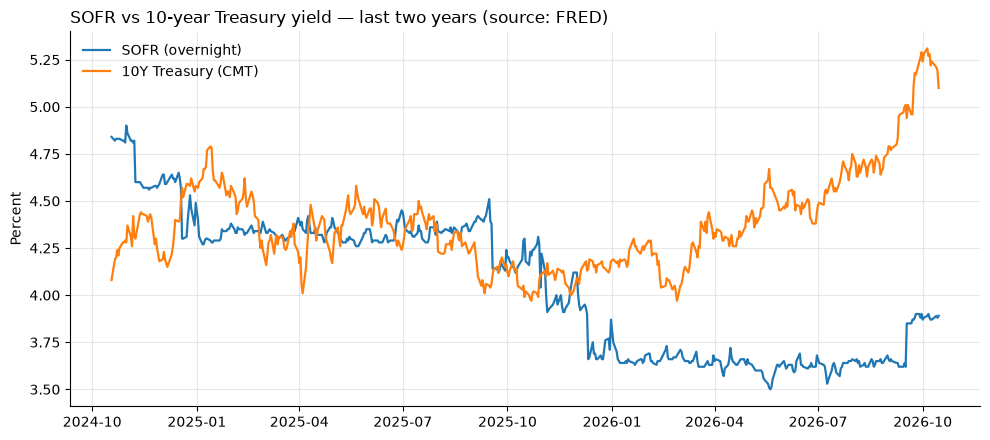

In [10]:
import matplotlib.pyplot as plt

if "sofr" in CACHE:
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(CACHE["sofr"].index, CACHE["sofr"].values, label="SOFR (overnight)", lw=1.6)
    ax.plot(CACHE["ust10"].index, CACHE["ust10"].values, label="10Y Treasury (CMT)", lw=1.6)
    ax.set_title("SOFR vs 10-year Treasury yield — last two years (source: FRED)", loc="left")
    ax.set_ylabel("Percent")
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    plt.tight_layout()
    plt.show()
else:
    print("FRED check did not succeed, so there is nothing to plot yet. Fix it above and rerun.")

---
*Next step:* once every row you need is ✅ (or ⚠️ / ℹ️), you're ready for Paquete 1.